# 02 · Classical machine learning: LDA and linear SVM on 96 window features

LDA and SVM need one fixed-length vector per trial. Each 12 × 128 epoch is summarised into 12 channels × 8 window means of 125 ms = 96 interpretable features.

*Data: Gao et al. (2014), public Dryad release, doi:10.5061/dryad.2qc64. Own analysis; the plan (folds, training task, decision rule) was fixed before results.*

In [1]:
import os, json, numpy as np, matplotlib.pyplot as plt
# Point GAO_DIR at the "14 electrodes-30 subjects" folder of the Dryad release; GKT_WORK holds all derived files
os.environ.setdefault("GAO_DIR", "./data/14 electrodes-30 subjects/")
os.environ.setdefault("GKT_WORK", "./work/")
from gkt_utils import *
print("data:", GAO_DIR, "| work:", WORK)

data: ./data/14 electrodes-30 subjects/ | work: ./work/


In [2]:
X, G, PID, SES, STIM = load_dataset()
PIDS = sorted(set(PID.tolist()))
print(X.shape, "epochs x channels x samples |", len(PIDS), "people |",
      {k: int((STIM == v).sum()) for k, v in STIM_CODE.items()})

(23388, 12, 128) epochs x channels x samples | 30 people | {'irrelevant': 15583, 'probe': 3890, 'target': 3915}


In [3]:
F = window_means(X)
print("feature matrix:", F.shape)

feature matrix: (23388, 96)


## Leave-one-pair-out training
Fold *k* holds out one knowledgeable (L*k*) and one control (H*k*) person. The models learn **target vs irrelevant** epochs from the other 28 people; probe epochs are never used in training. Standardisation is fitted on training people only.

In [4]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
scores = {m: np.full(len(X), np.nan) for m in ("LDA", "SVM")}
for k, (pl, ph) in enumerate(PAIRS, 1):
    te = np.isin(PID, [pl, ph]); tr = (~te) & (STIM != 1)
    y = (STIM[tr] == 2).astype(int)
    sc = StandardScaler().fit(F[tr]); A, B = sc.transform(F[tr]), sc.transform(F[te])
    lda = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto", priors=[0.5, 0.5]).fit(A, y)
    svm = LinearSVC(C=1.0, class_weight="balanced", max_iter=20000, random_state=0).fit(A, y)
    scores["LDA"][te] = lda.decision_function(B); scores["SVM"][te] = svm.decision_function(B)
    print(f"fold {k:2d}: test {code(pl)} + {code(ph)}, trained on {tr.sum()} epochs")
for m in scores: np.save(P(f"scores_{m}.npy"), scores[m])

fold  1: test L01 + H01, trained on 18149 epochs


fold  2: test L02 + H02, trained on 18386 epochs


fold  3: test L03 + H03, trained on 18433 epochs


fold  4: test L04 + H04, trained on 18229 epochs


fold  5: test L05 + H05, trained on 18267 epochs


...

fold 11: test L11 + H11, trained on 18045 epochs


fold 12: test L12 + H12, trained on 18000 epochs


fold 13: test L13 + H13, trained on 18213 epochs


fold 14: test L14 + H14, trained on 18460 epochs


fold 15: test L15 + H15, trained on 17968 epochs


In [5]:
for m in ("LDA", "SVM"):
    summ, persons = evaluate(scores[m], PID, STIM)
    show(summ, m); print("   errors:", [r["code"] for r in persons if r["decision"] != r["group"]])
    json.dump(dict(summary=summ, persons=persons), open(P(f"results_{m}.json"), "w"), indent=1)

LDA                      trial AUC 0.896 | person AUC 0.942 (perm p = 0.0001) | detected 14/15 | cleared 13/15 | BA 0.900
   errors: ['H08', 'H14', 'L01']


SVM                      trial AUC 0.896 | person AUC 0.942 (perm p = 0.0001) | detected 14/15 | cleared 12/15 | BA 0.867
   errors: ['H08', 'H14', 'H15', 'L01']


## What did LDA learn?
Refit LDA on all 30 people (for display only, not for evaluation) and show the 96 weights as a channel × window map.

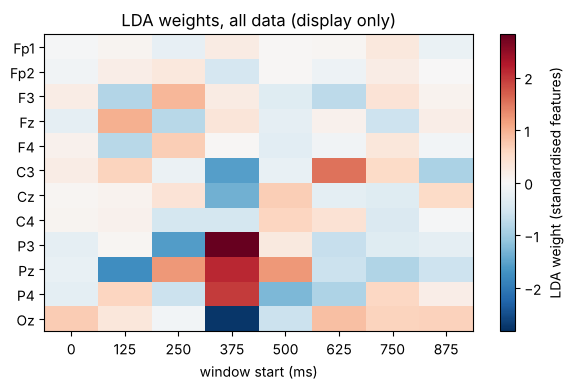

In [6]:
sc = StandardScaler().fit(F[STIM != 1]); lda = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto", priors=[.5, .5])
lda.fit(sc.transform(F[STIM != 1]), (STIM[STIM != 1] == 2).astype(int))
W = lda.coef_.reshape(12, 8)[FRONT_TO_BACK]
plt.figure(figsize=(6, 4)); plt.imshow(W, cmap="RdBu_r", aspect="auto", vmin=-abs(W).max(), vmax=abs(W).max())
plt.yticks(range(12), [EEG[i] for i in FRONT_TO_BACK]); plt.xticks(range(8), [f"{i*125}" for i in range(8)])
plt.xlabel("window start (ms)"); plt.colorbar(label="LDA weight (standardised features)"); plt.title("LDA weights, all data (display only)")
plt.tight_layout(); plt.show()

Expected: LDA 14/15 detected, 13/15 cleared (BA 0.90); SVM 14/15, 12/15 (BA 0.87). Shared errors: L01 missed, H08 flagged.